In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import drive

In [2]:
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
dataset = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/datasets/Posisi_gaji.csv')

In [4]:
X = dataset.iloc[:,1:2].values
y = dataset.iloc[:,2].values

In [5]:
from sklearn.preprocessing import StandardScaler
sc_X = StandardScaler()
sc_y = StandardScaler()
X = sc_X.fit_transform(X.reshape(-1,1))
y = sc_y.fit_transform(y.reshape(-1,1))

In [6]:
from sklearn.svm import SVR
regressor = SVR(kernel='rbf')
regressor.fit(X,y)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


SVR()

/tmp/ipykernel_1781/3990780622.py:1: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  X_grid = np.arange(min(X), max(X), 0.01).reshape(-1,1)


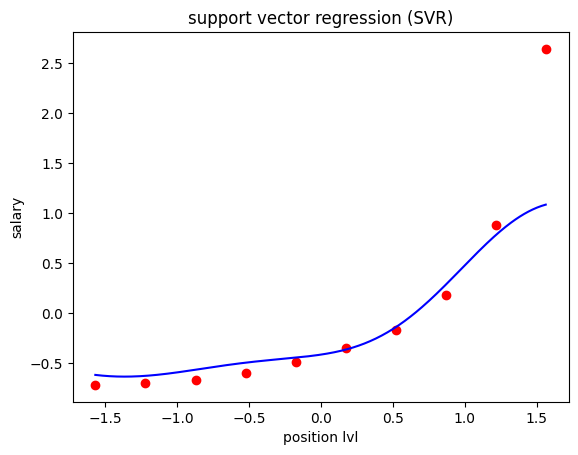

In [8]:
X_grid = np.arange(min(X), max(X), 0.01).reshape(-1,1)

plt.scatter(X,y, color='red')
plt.plot(X_grid, regressor.predict(X_grid), color='blue')
plt.title('support vector regression (SVR)')
plt.xlabel('position lvl')
plt.ylabel('salary')
plt.show()

In [9]:
position_level_pred = np.array([[6.5]])
position_level_pred = sc_X.transform(position_level_pred)

salary_pred = regressor.predict(position_level_pred)
salary_pred = sc_y.inverse_transform(salary_pred.reshape(-1,1))

In [10]:
print("predicted salary for position level 6.5: ", salary_pred[0])

predicted salary for position level 6.5:  [170370.0204065]


In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_actual = y
y_pred = regressor.predict(X)

mae = mean_absolute_error(y_actual, y_pred)
mse = mean_squared_error(y_actual, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_actual, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R-squared:", r2)

MAE: 0.22299274095734414
MSE: 0.24839989293792014
RMSE: 0.4983973243687411
R-squared: 0.7516001070620798
